In [1]:
import pickle
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
belief_col = "Belief_opinion_on_january_6th_storming_of_the_us_capitol_Symbol"

In [3]:
with open(f"/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/Dropped_ICAR_MrP/{belief_col}_stan_output/fit.pkl", "rb") as f:
    fit = pickle.load(f)

/home/yuyue/stan_env/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
df = pd.read_pickle('/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/preprocessed_cleaned_all_result.pkl')

In [5]:
strat_df = pd.read_csv("/mnt/c/Users/yuyue/Dropbox/is_culture_king/is_culture_king_Yuyue/generated_data/feature_extraction/cleaned_sf.csv")

In [6]:
strat_df

,Unnamed: 0,sex_idx,age_idx,eth_idx,income_idx,state_idx,vote_idx,N_star.1,N_star.2,N_star.3,...,LP_pct.2020.votes.G,LP_pct.2020.votes.stay.home,LP_pct.2020.votes.OTHER,LP_pct.2022.votes.D,LP_pct.2022.votes.R,LP_pct.2022.votes.L,LP_pct.2022.votes.G,LP_pct.2022.votes.stay.home,LP_pct.2022.votes.OTHER,state_abbreviation_upper
0,0,2,1,4,1,1,1,1.867455,0.548105,1.565072,...,-0.997116,-0.154947,2.071398,0.286556,-0.196120,0.136231,-0.175703,-0.514353,-0.467282,AK
1,1,2,1,4,1,1,2,0.013752,0.139760,0.207898,...,-0.997116,-0.154947,2.071398,0.286556,-0.196120,0.136231,-0.175703,-0.514353,-0.467282,AK
2,2,2,1,4,1,1,3,0.264992,1.602773,0.317292,...,-0.997116,-0.154947,2.071398,0.286556,-0.196120,0.136231,-0.175703,-0.514353,-0.467282,AK
3,3,2,1,4,1,1,4,0.001838,0.007018,0.013940,...,-0.997116,-0.154947,2.071398,0.286556,-0.196120,0.136231,-0.175703,-0.514353,-0.467282,AK
4,4,2,1,4,1,1,5,0.000000,0.000000,0.000000,...,-0.997116,-0.154947,2.071398,0.286556,-0.196120,0.136231,-0.175703,-0.514353,-0.467282,AK
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
110155,110155,1,6,1,5,51,2,23.309498,26.801340,33.842180,...,-0.997116,0.314307,2.264716,-1.463526,1.104902,0.441713,-0.175703,0.042198,1.215613,WY
110156,110156,1,6,1,5,51,3,17.174077,19.340563,9.853957,...,-0.997116,0.314307,2.264716,-1.463526,1.104902,0.441713,-0.175703,0.042198,1.215613,WY
110157,110157,1,6,1,5,51,4,0.102195,0.023442,0.284320,...,-0.997116,0.314307,2.264716,-1.463526,1.104902,0.441713,-0.175703,0.042198,1.215613,WY
110158,110158,1,6,1,5,51,5,0.000000,0.000000,0.000000,...,-0.997116,0.314307,2.264716,-1.463526,1.104902,0.441713,-0.175703,0.042198,1.215613,WY


In [7]:
print(df['state_cleaned_idx'].value_counts())

state_cleaned_idx
5.0     966
35.0    743
44.0    556
10.0    551
39.0    350
48.0    283
46.0    254
4.0     219
20.0    209
6.0     188
11.0    187
36.0    181
43.0    179
32.0    177
24.0    169
15.0    166
28.0    165
23.0    163
8.0     154
34.0    128
21.0    127
38.0    126
41.0    122
49.0     95
17.0     93
45.0     80
13.0     80
16.0     67
18.0     65
19.0     58
2.0      54
7.0      48
3.0      42
12.0     39
9.0      36
27.0     32
14.0     32
31.0     30
25.0     25
51.0     18
33.0     17
26.0     16
42.0     15
37.0     13
40.0     11
47.0     10
22.0      9
30.0      8
Name: count, dtype: int64


In [8]:
posterior_draws = fit.draws_pd()

In [9]:
eta_sex = posterior_draws.filter(regex="eta_sex_star")
eta_age = posterior_draws.filter(regex="eta_age_star")
eta_eth = posterior_draws.filter(regex="eta_eth_star")
eta_income = posterior_draws.filter(regex="eta_income_star")
eta_vote = posterior_draws.filter(regex="eta_vote_star")
beta_lp = posterior_draws.filter(regex=r"^beta_LP\[")
# Only keep structured state effects (exclude raw/other variants)
eta_state = posterior_draws.filter(regex=r"^eta_state\[")


In [10]:
def summarize_effect(df):
    mean = df.mean()
    lower = df.quantile(0.025)
    upper = df.quantile(0.975)
    summary = pd.DataFrame({"mean": mean, "2.5%": lower, "97.5%": upper})
    return summary

sex_summary = summarize_effect(eta_sex)
age_summary = summarize_effect(eta_age)
eth_summary = summarize_effect(eta_eth)
income_summary = summarize_effect(eta_income)
vote_summary = summarize_effect(eta_vote)
lp_summary = summarize_effect(beta_lp)
state_summary = summarize_effect(eta_state)


In [11]:
sex_summary

,mean,2.5%,97.5%
eta_sex_star[1],0.037586,-0.017642,0.099887
eta_sex_star[2],-0.037586,-0.099887,0.017642


In [12]:
sex_labels = {
    "eta_sex_star[1]": "Male",
    "eta_sex_star[2]": "Female"
}

age_labels = {
    "eta_age_star[1]": "18-24",
    "eta_age_star[2]": "25-34",
    "eta_age_star[3]": "35-44",
    "eta_age_star[4]": "45-54",
    "eta_age_star[5]": "55-64",
    "eta_age_star[6]": "65+"
}

ethnicity_labels = {
    "eta_eth_star[1]": "White",
    "eta_eth_star[2]": "Black",
    "eta_eth_star[3]": "Hispanic",
    "eta_eth_star[4]": "Asian",
    "eta_eth_star[5]": "American Indian",
    "eta_eth_star[6]": "Other"
}

income_labels = {
    "eta_income_star[1]": "<$25k",
    "eta_income_star[2]": "$25k-$50k",
    "eta_income_star[3]": "$50k-$75k",
    "eta_income_star[4]": "$75k-$100k",
    "eta_income_star[5]": ">$100k"
}

vote_labels = {
    "eta_vote_star[1]": "Did not vote",
    "eta_vote_star[2]": "Republican",
    "eta_vote_star[3]": "Democrat",
    "eta_vote_star[4]": "Libertarian",
    "eta_vote_star[5]": "Green",
    "eta_vote_star[6]": "Other"
}

lp_labels = {
    "beta_LP[1]": "2020 R votes %",
    "beta_LP[2]": "2020 stay home %",
    "beta_LP[3]": "2022 R votes %",
    "beta_LP[4]": "2022 stay home %"
}


In [13]:
# Extract state labels from strat_df using state_idx mapping to state_abbreviation_upper
state_lookup = (
    strat_df[["state_idx", "state_abbreviation_upper"]]
    .dropna()
    .drop_duplicates()
    .sort_values("state_idx")
)
state_labels = {
    f"eta_state[{int(idx)}]": abbr
    for idx, abbr in zip(state_lookup["state_idx"], state_lookup["state_abbreviation_upper"])
}
state_labels_raw = {
    f"eta_state_raw[{int(idx)}]": abbr
    for idx, abbr in zip(state_lookup["state_idx"], state_lookup["state_abbreviation_upper"])
}

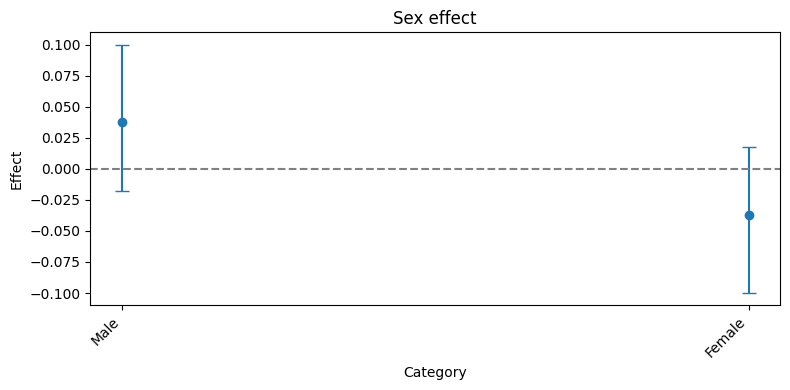

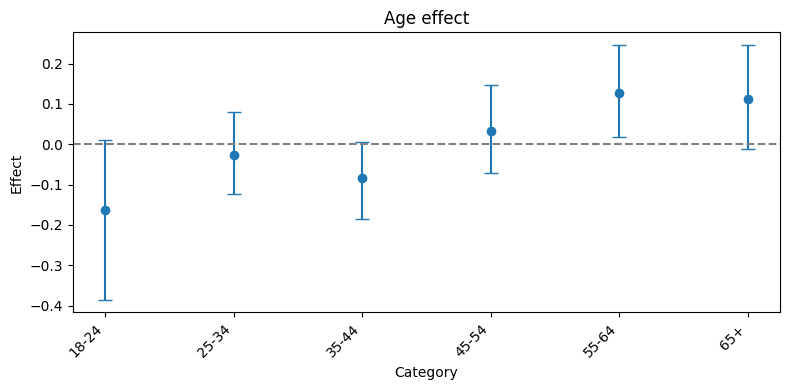

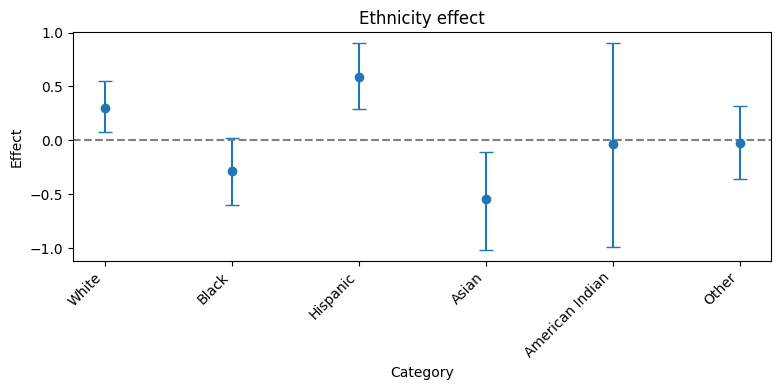

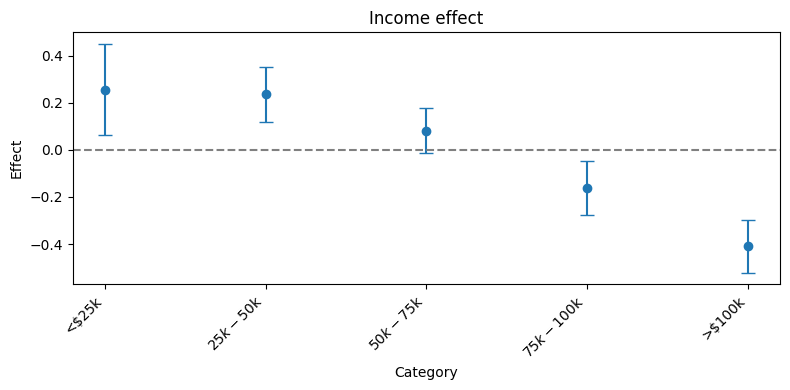

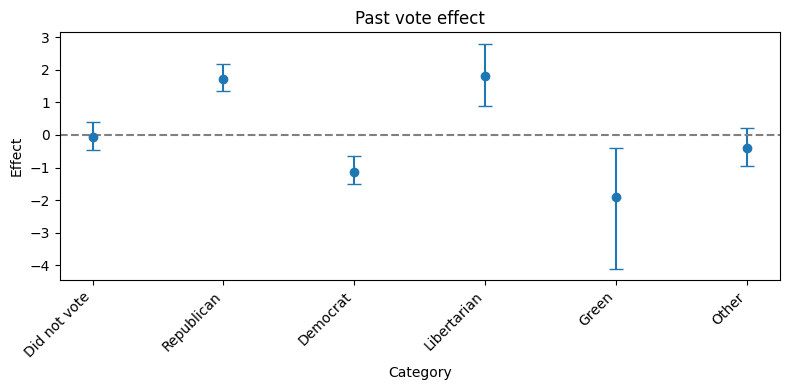

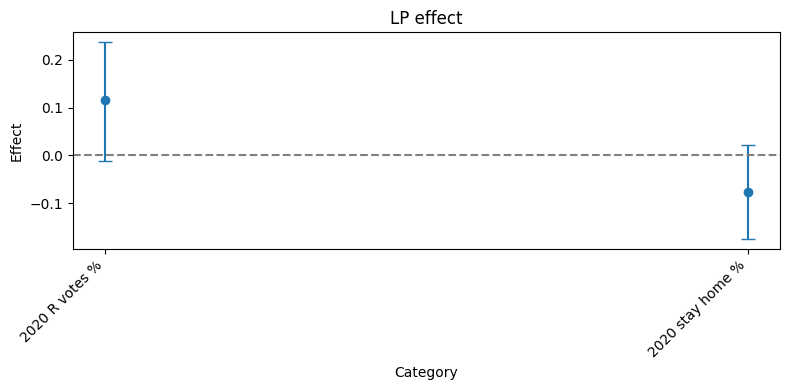

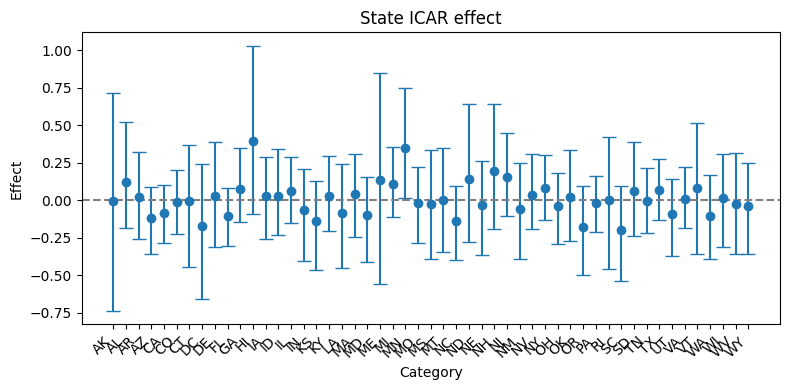

In [14]:
def plot_effect(summary, title, label_map=None):
    plt.figure(figsize=(8,4))

    x = summary.index
    y = summary["mean"]
    yerr = [
        summary["mean"] - summary["2.5%"],
        summary["97.5%"] - summary["mean"]
    ]

    plt.errorbar(x=x, y=y, yerr=yerr, fmt='o', capsize=5)
    plt.axhline(0, color='gray', linestyle='--')
    plt.title(title)
    plt.xlabel("Category")
    plt.ylabel("Effect")

    if label_map is not None:
        labels = [label_map.get(i, i) for i in x]
        plt.xticks(x, labels, rotation=45, ha="right")

    plt.tight_layout()
    plt.show()

plot_effect(sex_summary, "Sex effect", sex_labels)
plot_effect(age_summary, "Age effect", age_labels)
plot_effect(eth_summary, "Ethnicity effect", ethnicity_labels)
plot_effect(income_summary, "Income effect", income_labels)
plot_effect(vote_summary, "Past vote effect", vote_labels)
plot_effect(lp_summary, "LP effect", lp_labels)
plot_effect(state_summary, "State ICAR effect", state_labels)


In [18]:
# Quick diagnostics for specific states (IA, AL)
def show_state_diagnostics(abbrev):
    row = state_lookup[state_lookup["state_abbreviation_upper"] == abbrev]
    if row.empty:
        print(f"No mapping found for {abbrev}")
        return
    idx = int(row["state_idx"].iloc[0])
    key = f"eta_state[{idx}]"
    print(f"State {abbrev} (idx {idx})")
    if key in state_summary.index:
        print(state_summary.loc[key])
    else:
        print(f"No summary row for {key}")
    if key in eta_state.columns:
        print("posterior sd:", eta_state[key].std())
    if "state_cleaned_idx" in df.columns:
        print("n obs in df:", (df["state_cleaned_idx"] == idx).sum())
    if "state_idx" in strat_df.columns:
        print("n rows in strat_df:", (strat_df["state_idx"] == idx).sum())
    print("----")

show_state_diagnostics("HI")
show_state_diagnostics("AK")


State HI (idx 12)
mean     0.560792
2.5%    -0.071644
97.5%    1.300413
Name: eta_state[12], dtype: float64
posterior sd: 0.36914308733856577
n obs in df: 39
n rows in strat_df: 2160
----
State AK (idx 1)
mean     0.002429
2.5%    -2.091565
97.5%    2.064945
Name: eta_state[1], dtype: float64
posterior sd: 0.9638745631991792
n obs in df: 0
n rows in strat_df: 2160
----


In [19]:
# Summary table for all states
state_diagnostics = []
for col in eta_state.columns:
    idx = int(col.split("[")[1].split("]")[0])
    abbrev = state_labels.get(col, "?")
    mean_eff = state_summary.loc[col, "mean"]
    width = state_summary.loc[col, "97.5%"] - state_summary.loc[col, "2.5%"]
    sd = eta_state[col].std()
    n_obs = (df["state_cleaned_idx"] == idx).sum() if "state_cleaned_idx" in df.columns else 0
    state_diagnostics.append({
        "state": abbrev,
        "idx": idx,
        "mean": mean_eff,
        "CI_width": width,
        "post_sd": sd,
        "n_obs": n_obs
    })

state_diag_df = pd.DataFrame(state_diagnostics).sort_values("CI_width", ascending=False)
print("States by credible interval width:")
state_diag_df.head(10)


States by credible interval width:


,state,idx,mean,CI_width,post_sd,n_obs
0,AK,1,0.002429,4.156510,0.963875,0
11,HI,12,0.560792,1.372057,0.369143,39
21,ME,22,0.000013,0.013911,0.003334,9
30,NH,31,0.000026,0.010993,0.002610,30
46,VT,47,0.000032,0.010354,0.002390,10
39,RI,40,0.000029,0.010257,0.002343,11
6,CT,7,0.000007,0.010028,0.002337,48
19,MA,20,0.000008,0.009540,0.002228,209
47,WA,48,-0.000052,0.009281,0.002105,283
9,FL,10,-0.000055,0.008853,0.002090,551


In [15]:
# Compare magnitude of effects across all parameters
print("Effect magnitude comparison :")
print(f"Sex:       {sex_summary['mean'].abs().mean():.4f}")
print(f"Age:       {age_summary['mean'].abs().mean():.4f}")
print(f"Ethnicity: {eth_summary['mean'].abs().mean():.4f}")
print(f"Income:    {income_summary['mean'].abs().mean():.4f}")
print(f"Vote:      {vote_summary['mean'].abs().mean():.4f}")
print(f"State:     {state_summary['mean'].abs().mean():.4f}")
print(f"State (excl HI/AK): {state_summary.drop(['eta_state[1]', 'eta_state[12]'], errors='ignore')['mean'].abs().mean():.4f}")


Effect magnitude comparison :
Sex:       0.0376
Age:       0.0909
Ethnicity: 0.2976
Income:    0.2276
Vote:      1.1743
State:     0.0816
State (excl HI/AK): 0.0768


In [16]:
# Check if there's a spatial variance/precision parameter
spatial_params = [col for col in posterior_draws.columns if 'tau' in col.lower() or 'sigma' in col.lower() or 'state' in col.lower()]
spatial_hyperparams = [p for p in spatial_params if '[' not in p]  # Exclude indexed parameters
print("Spatial hyperparameters found:")
for param in spatial_hyperparams[:10]:  # Show first 10
    print(f"{param}: mean = {posterior_draws[param].mean():.4f}, sd = {posterior_draws[param].std():.4f}")


Spatial hyperparameters found:
sigma_sex: mean = 0.3425, sd = 0.4090
sigma_age: mean = 0.1650, sd = 0.1090
sigma_eth: mean = 0.5390, sd = 0.2363
sigma_income: mean = 0.3100, sd = 0.1695
sigma_vote: mean = 1.3951, sd = 0.4128
sigma_state: mean = 0.3239, sd = 0.1215


Found 7357 LP-related columns
lp__: mean = -4872.9414, sd = 9.2425
log_lik[1]: mean = -0.5061, sd = 0.0313
log_lik[2]: mean = -1.2176, sd = 0.1007
log_lik[3]: mean = -0.5061, sd = 0.0313
log_lik[4]: mean = -0.1506, sd = 0.0223


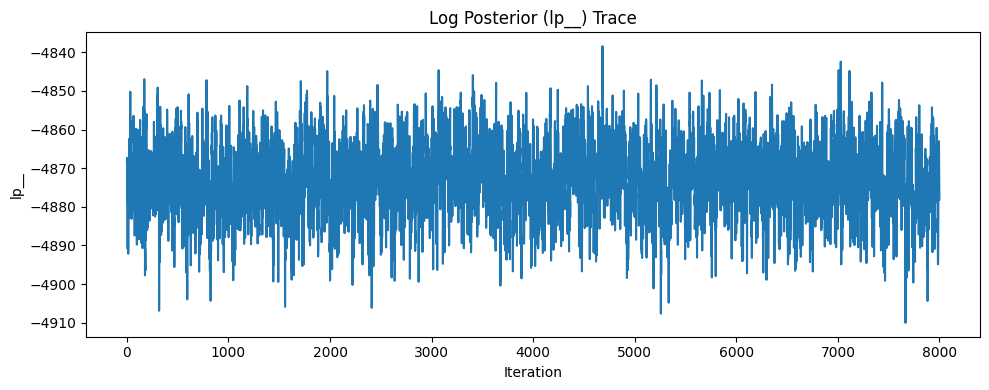

In [17]:
# Extract and plot LP (linear predictor) effects
lp_cols = [col for col in posterior_draws.columns if col.startswith('lp') or 'log_lik' in col or col == 'lp__']
print(f"Found {len(lp_cols)} LP-related columns")

if lp_cols:
    # Show LP diagnostics
    for col in lp_cols[:5]:  # Show first 5
        print(f"{col}: mean = {posterior_draws[col].mean():.4f}, sd = {posterior_draws[col].std():.4f}")
    
    # Plot LP trace if lp__ exists
    if 'lp__' in lp_cols:
        plt.figure(figsize=(10, 4))
        plt.plot(posterior_draws['lp__'])
        plt.title("Log Posterior (lp__) Trace")
        plt.xlabel("Iteration")
        plt.ylabel("lp__")
        plt.tight_layout()
        plt.show()
else:
    print("No LP columns found in posterior draws")


In [18]:
# Check correlation between LP state-level predictors
LP_cols = [
    'LP_pct.2020.votes.R', 'LP_pct.2020.votes.stay.home',
    'LP_pct.2022.votes.R', 'LP_pct.2022.votes.stay.home'
]
LP_state = (
    strat_df
    .groupby("state_abbreviation")[LP_cols]
    .mean()
)

print("Correlation matrix of LP predictors:")
print(LP_state.corr().round(3))
print("\n")

# Check if LP effects' credible intervals exclude zero
print("LP coefficients (beta_LP):")
print(lp_summary)
print("\nDo credible intervals exclude zero?")
for idx, row in lp_summary.iterrows():
    excludes_zero = (row["2.5%"] > 0) or (row["97.5%"] < 0)
    print(f"{lp_labels.get(idx, idx)}: {'Yes' if excludes_zero else 'No'} (mean={row['mean']:.4f})")


Correlation matrix of LP predictors:
                             LP_pct.2020.votes.R  LP_pct.2020.votes.stay.home  \
LP_pct.2020.votes.R                        1.000                        0.343   
LP_pct.2020.votes.stay.home                0.343                        1.000   
LP_pct.2022.votes.R                        0.958                        0.324   
LP_pct.2022.votes.stay.home                0.282                        0.832   

                             LP_pct.2022.votes.R  LP_pct.2022.votes.stay.home  
LP_pct.2020.votes.R                        0.958                        0.282  
LP_pct.2020.votes.stay.home                0.324                        0.832  
LP_pct.2022.votes.R                        1.000                        0.322  
LP_pct.2022.votes.stay.home                0.322                        1.000  


LP coefficients (beta_LP):
                mean      2.5%     97.5%
beta_LP[1]  0.115660 -0.010985  0.237220
beta_LP[2] -0.075877 -0.175326  0.022031

Do c

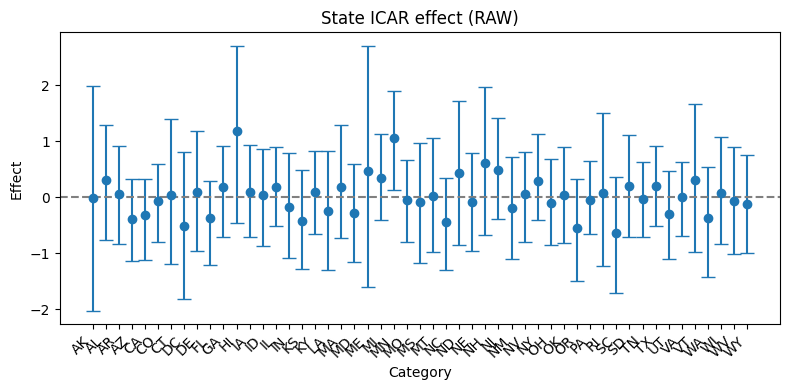

Raw state effects summary:
                       mean      2.5%     97.5%
eta_state_raw[1]  -0.008543 -2.036733  1.978802
eta_state_raw[2]   0.313602 -0.769363  1.285878
eta_state_raw[3]   0.046429 -0.838372  0.911859
eta_state_raw[4]  -0.385130 -1.146803  0.316209
eta_state_raw[5]  -0.311227 -1.120179  0.322594
eta_state_raw[6]  -0.067940 -0.795163  0.594219
eta_state_raw[7]   0.039283 -1.194637  1.403529
eta_state_raw[8]  -0.513896 -1.811817  0.811643
eta_state_raw[9]   0.088714 -0.958784  1.186071
eta_state_raw[10] -0.372884 -1.211089  0.287883
eta_state_raw[11]  0.181955 -0.707615  0.911062
eta_state_raw[12]  1.183179 -0.464437  2.694869
eta_state_raw[13]  0.098902 -0.711416  0.929549
eta_state_raw[14]  0.041960 -0.878618  0.861752
eta_state_raw[15]  0.184915 -0.513682  0.892414
eta_state_raw[16] -0.181379 -1.083322  0.785821
eta_state_raw[17] -0.418608 -1.279236  0.479731
eta_state_raw[18]  0.083794 -0.652981  0.826045
eta_state_raw[19] -0.253146 -1.300198  0.827405
eta_state_raw

In [19]:
# Extract raw state ICAR effects
eta_state_raw = posterior_draws.filter(regex=r"^eta_state_raw\[")

# Summarize raw effects
raw_state_summary = summarize_effect(eta_state_raw)

# Plot raw effects with state labels
plot_effect(raw_state_summary, "State ICAR effect (RAW)", state_labels_raw)

# Print comparison
print("Raw state effects summary:")
print(raw_state_summary)